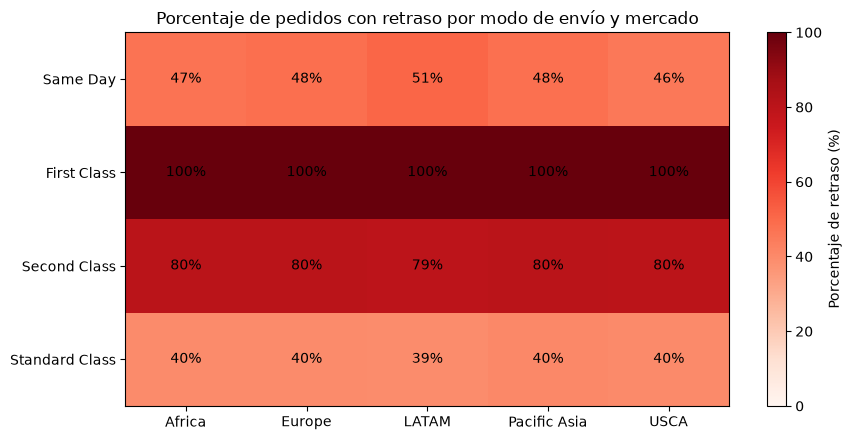

In [17]:
import pandas as pd
import matplotlib.pyplot as plt

query = """
WITH pedidos AS (
    SELECT DISTINCT
        f.Order_Id,
        ds.Shipping_Mode AS modo,
        o.Market AS mercado,
        CASE WHEN f.Days_For_Shipping_Real > f.Days_For_Shipment_Scheduled
             THEN 1 ELSE 0 END AS retraso
    FROM FactSales f
    INNER JOIN DimShipping ds ON ds.Shipping_Key = f.Shipping_Key
    INNER JOIN DimOrder o ON o.Order_Id = f.Order_Id
    WHERE o.Order_Status NOT IN ('CANCELED', 'SUSPECTED_FRAUD')
)
SELECT modo, mercado, COUNT(*) AS pedidos, AVG(retraso * 1.0) * 100 AS pct_retraso
FROM pedidos
GROUP BY modo, mercado
"""
r = pd.read_sql(query, engine)

tabla = r.pivot(index="modo", columns="mercado", values = "pct_retraso")
tabla = tabla.reindex(["Same Day", "First Class", "Second Class", "Standard Class"])

fig, ax = plt.subplots(figsize=(9, 4.5))
im = ax.imshow(tabla.values, cmap="Reds", vmin=0, vmax=100, aspect="auto")

ax.set_xticks(range(len(tabla.columns)))
ax.set_xticklabels(tabla.columns)
ax.set_yticks(range(len(tabla.index)))
ax.set_yticklabels(tabla.index)


for i in range(tabla.shape[0]):
    for j in range(tabla.shape[1]):
        ax.text(j, i, f"{tabla.values[i, j]:.0f}%", ha="center", va="center",
                color="black", fontsize=10)

ax.set_title("Porcentaje de pedidos con retraso por modo de envío y mercado")
fig.colorbar(im, ax=ax, label="Porcentaje de retraso (%)")
plt.tight_layout()
plt.savefig("py_retraso_modo_mercado.png", dpi=150)
plt.show()


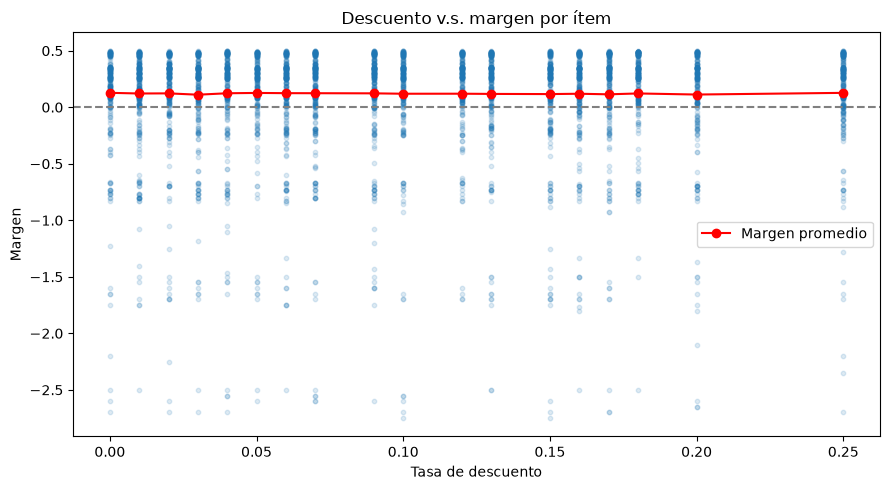

In [18]:
import matplotlib.pyplot as plt

muestra = df.sample(5000, random_state=42)

fig, ax = plt.subplots(figsize=(9, 5))

ax.scatter(muestra["descuento"], muestra["margen"], alpha=0.15, s=10)

prom = df.groupby("descuento")["margen"].mean()
ax.plot(prom.index, prom.values, color="red", marker="o", label="Margen promedio")

ax.axhline(0, color="gray", linestyle="--")
ax.set_title("Descuento v.s. margen por ítem")
ax.set_xlabel("Tasa de descuento")
ax.set_ylabel("Margen")
ax.legend()

plt.tight_layout()
plt.savefig("py_descuento_vs_margen.png", dpi=150)
plt.show()

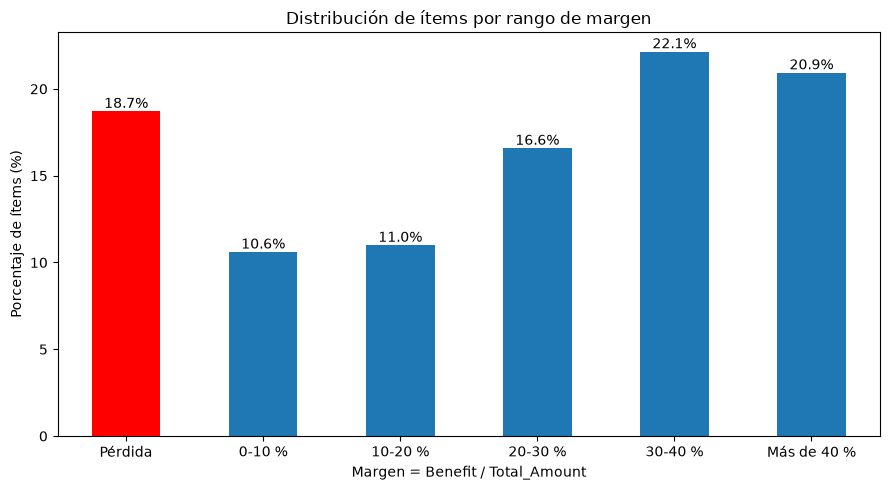

In [19]:
import pandas as pd
import matplotlib.pyplot as plt

rangos = [-float("inf"), 0, 0.1, 0.2, 0.3, 0.4, float("inf")]
etiquetas = ["Pérdida", "0-10 %", "10-20 %", "20-30 %", "30-40 %", "Más de 40 %"]
df["rango_margen"] = pd.cut(df["margen"], bins=rangos, labels=etiquetas, right=False)

pct = df["rango_margen"].value_counts(normalize=True).reindex(etiquetas) * 100

ax = pct.plot(kind="bar", color=["red"] + ["tab:blue"] * 5, figsize=(9, 5))
ax.bar_label(ax.containers[0], fmt="%.1f%%")
ax.set_title("Distribución de ítems por rango de margen")
ax.set_xlabel("Margen = Benefit / Total_Amount")
ax.set_ylabel("Porcentaje de ítems (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("py_distribucion_margen.png", dpi=150)
plt.show()